In [1]:
import sklearn
import pickle
import numpy as np
import glob
from sklearn.decomposition import PCA, KernelPCA
import matplotlib.pyplot as plt

In [2]:
directory="/Users/z3079335/OneDrive - UNSW/Documents/Projects/So3krates/LLZO/llzo_12_44/soap_kernel_AIMD_warmup_traj/long_range_kernel"
all_pickles=glob.glob(directory+'/kernel*bp')
print(len(all_pickles))

520


In [3]:
all_energies = []
kernel_parts = []
for i in range(len(all_pickles)):
    data=pickle.load(open(directory+'/kernel_part_'+str(i)+'.bp','rb'))
    all_energies+=data[1]
    kernel_parts.append(data[0])


kernel=np.zeros([len(all_energies),len(all_energies)])
dim=np.shape(kernel_parts[0])[0]

for i in range(len(kernel_parts)):
    try:
        kernel[i*dim:(i+1)*dim,:]=kernel_parts[i]
    except:
        pass

#for i in range(np.shape(kernel)[0]):
#    for j in range(i,np.shape(kernel)[0]):
#        kernel[j][i]=kernel[i][j]

In [4]:
kpca = KernelPCA(n_components=None, kernel="precomputed", fit_inverse_transform=False)
X_kpca = kpca.fit_transform(kernel)

/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_31031/889984100.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cm = plt.cm.get_cmap('coolwarm')


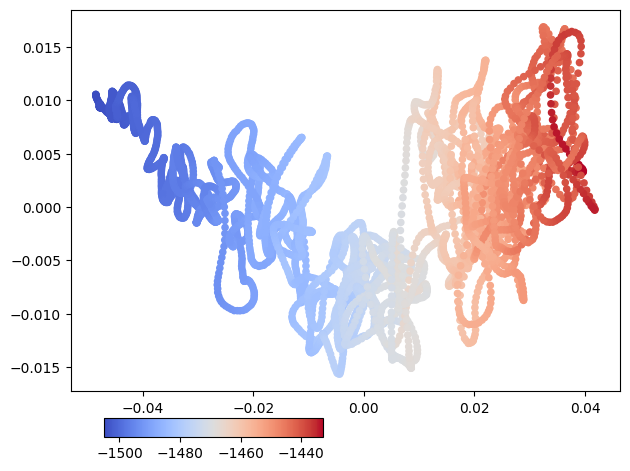

In [5]:
fig, ax = plt.subplots()
cm = plt.cm.get_cmap('coolwarm')
aplot = ax.scatter(-X_kpca[:, 0], X_kpca[:, 1], c=all_energies[:], alpha=1, cmap=cm, s=20)
cbaxes = ax.inset_axes([0.06, -0.12, 0.4, 0.05])
cbar = fig.colorbar(aplot, cax=cbaxes, orientation='horizontal')
#plt.axis('off')
plt.tight_layout()

/Users/z3079335/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/z3079335/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/z3079335/anaconda3/lib/python3.11/site-packages/seaborn/distributions.py:1185: UserWarning: The following kwargs were not used by contour: 'linewidth'
  cset = contour_func(


<Axes: >

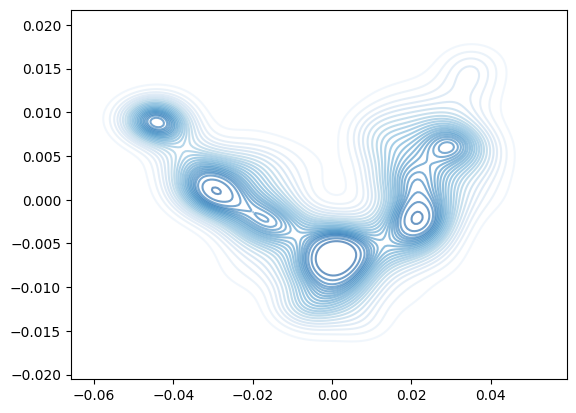

In [6]:
import seaborn as sns

sns.kdeplot(x=-X_kpca[:, 0], y=X_kpca[:, 1], levels=25, thresh=0, fill=False, cmap='Blues',linewidth=1,alpha=0.6)

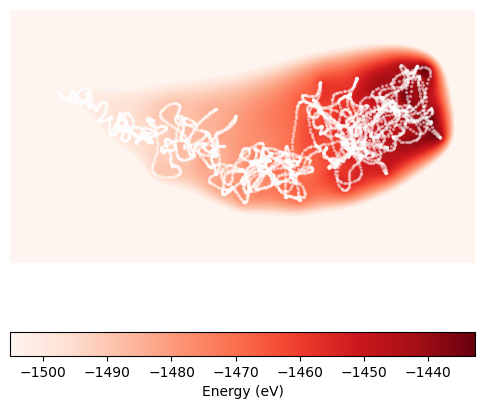

In [29]:
import scipy.interpolate
plt.figure(figsize=(6,6))
xi,yi=np.linspace(-0.06,0.05,550),np.linspace(-0.03,0.03,300)
xi,yi=np.meshgrid(xi,yi)
z = np.array(all_energies)
x = np.array(-X_kpca[:, 0])
y = np.array(X_kpca[:, 1])
rbf = scipy.interpolate.Rbf(x, y, z, function='linear')
zi = rbf(xi,yi)

plt.imshow(zi, vmin=z.min(), vmax=z.max(), origin='lower', extent=[xi.min(), xi.max(), yi.min(), yi.max()],cmap='Reds')
plt.axis('off')
plt.colorbar(orientation='horizontal',label='Energy (eV)')
plt.scatter(x,y,s=2,c='w',alpha=0.4)
plt.show()

In [11]:
directory="/Users/z3079335/OneDrive - UNSW/Documents/Projects/So3krates/LLZO/llzo_12_44/soap_kernel_AIMD_MLMD_compare"
all_pickles=glob.glob(directory+'/kernel*bp')
print(len(all_pickles))

all_energies = []
kernel_parts = []
for i in range(len(all_pickles)):
    data=pickle.load(open(directory+'/kernel_part_'+str(i)+'.bp','rb'))
    all_energies+=[data[1][j]['energy'] for j in range(len(data[1]))]
    kernel_parts.append(data[0])


kernel=np.zeros([len(all_energies),len(all_energies)])
dim=np.shape(kernel_parts[0])[0]

for i in range(len(kernel_parts)):
    try:
        kernel[i*dim:(i+1)*dim,:]=kernel_parts[i]
    except:
        pass

90


In [12]:
kpca = KernelPCA(n_components=None, kernel="precomputed", fit_inverse_transform=False)
X_kpca = kpca.fit_transform(kernel)

/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_55040/3048541934.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cm = plt.cm.get_cmap('coolwarm')


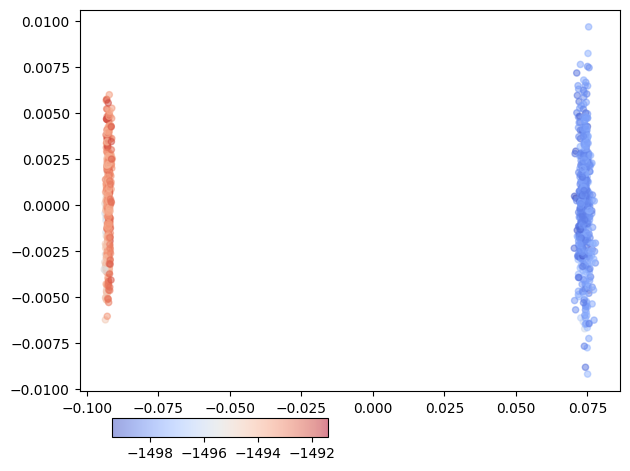

In [18]:
fig, ax = plt.subplots()
cm = plt.cm.get_cmap('coolwarm')
aplot = ax.scatter(-X_kpca[:, 0], X_kpca[:, 1], c=all_energies[:], alpha=0.5, cmap=cm, s=20)
cbaxes = ax.inset_axes([0.06, -0.12, 0.4, 0.05])
cbar = fig.colorbar(aplot, cax=cbaxes, orientation='horizontal')
#plt.axis('off')
plt.tight_layout()